[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C6_NB15_ann_surrogate_brains.ipynb)

# Day 2 · Chapter 6 · Notebook 15 — Neural networks as surrogate brains

Hands-on version of the Chapter 6 slides. We train the network of Luo et al. (2025) to predict the next frame of brain
activity, check it on data it has never seen, let it run on its own, and perturb it to read **who influences whom**.
To be able to check the answer, the "brain" is a simulation whose true wiring we know.

> **Question.** Can a network trained only to predict brain activity be used as a virtual brain, and does perturbing it
> reveal who influences whom? **Virtual experiment.** Push each region of the trained surrogate and read the response
> (as in NB14b, but on a learned model). **What would change our mind.** If the inferred directions were right no more
> often than chance (50 %).

In [1]:
# @title Setup (run once)
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
import torch, torch.nn as nn
from src import connectome
torch.manual_seed(0)

## 1. A brain whose wiring we know

> **Gist.** 148 regions wired by the mouse connectome (Allen tracer data: connections have a **direction**), each
> region a noisy unit that passes activity to its targets. We record 20 000 frames.

<details><summary>The simulated brain</summary>

$\dot x = -x + 0.9\,W x + \text{noise}$, with $W$ the directed mouse connectome scaled so that its largest eigenvalue is 1
(stable, close to the edge). Sampled every time unit; each region z-scored with the statistics of the training part.
It is linear on purpose: the point is to test the method where we know the truth, not to model the mouse brain.
</details>

In [2]:
# @title Simulate 20 000 frames of a noisy network on the directed mouse connectome (a few seconds)
scm, labm, _, _ = connectome.load_mouse()
N, S = len(scm), 3                                              # 148 regions, 3 past frames as input (as in the slides)
W = scm / np.max(np.abs(np.linalg.eigvals(scm)))                # largest eigenvalue 1
true = W.T                                                      # true[j, i]: connection from region j to region i
rng = np.random.default_rng(0); x, data = np.zeros(N), []
for k in range(20000 * 20):                                     # Euler steps of 0.05, one frame every 20 steps
    x = x + 0.05 * (-x + 0.9 * W @ x) + np.sqrt(0.05) * 0.5 * rng.standard_normal(N)
    if k % 20 == 0: data.append(x.copy())
data = np.array(data)
n_train = int(0.9 * len(data))                                  # first 90 % for training, last 10 % never seen
data = (data - data[:n_train].mean(0)) / data[:n_train].std(0)

def windows(z):
    # inputs: the last S frames (S x N numbers); target: the next frame (N numbers)
    X = np.stack([z[t - S:t] for t in range(S, len(z))]); Y = z[S:]
    return torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)

Xtr, Ytr = windows(data[:n_train]); Xte, Yte = windows(data[n_train:])
print(f"{N} regions; {len(Xtr)} training examples, {len(Xte)} test examples")

148 regions; 17997 training examples, 1997 test examples


## 2. Train the surrogate: training and test loss

> **Gist.** The MLP of the slides (3 frames → 2N → 0.8N → next frame) learns by gradient descent. After each pass over
> the training data (one **epoch**) we measure the loss on the training data and on the test data it never sees.

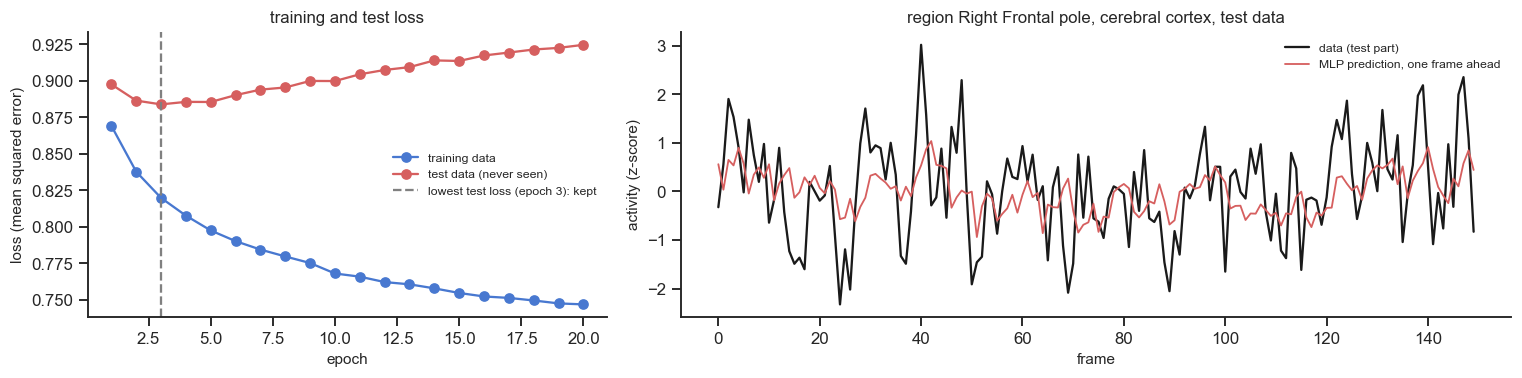

loss at the kept epoch: training 0.82, test 0.88


In [3]:
# @title Train the MLP of Luo et al. (2025) for 20 epochs and record training and test loss (about 10 s)
def make_mlp():
    return nn.Sequential(nn.Flatten(), nn.Linear(S * N, 2 * N), nn.ReLU(),
                         nn.Linear(2 * N, int(0.8 * N)), nn.ReLU(), nn.Linear(int(0.8 * N), N))

def train(model, Xtr, Ytr, Xte, Yte, epochs=20, seed=0):
    torch.manual_seed(seed); opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = lambda X, Y: ((model(X) - Y) ** 2).mean()          # mean squared error
    history, best = [], (np.inf, None)
    for epoch in range(epochs):
        for idx in torch.randperm(len(Xtr)).split(64):           # mini-batches of 64 examples
            loss = loss_fn(Xtr[idx], Ytr[idx]); opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad(): history.append((loss_fn(Xtr, Ytr).item(), loss_fn(Xte, Yte).item()))
        if history[-1][1] < best[0]: best = (history[-1][1], {k: v.clone() for k, v in model.state_dict().items()})
    model.load_state_dict(best[1])                              # keep the version with the lowest test loss
    return model, np.array(history)

mlp, history = train(make_mlp(), Xtr, Ytr, Xte, Yte)
best_epoch = int(np.argmin(history[:, 1])) + 1

fig, ax = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw=dict(width_ratios=[1, 1.6]))
ep = np.arange(1, len(history) + 1)
ax[0].plot(ep, history[:, 0], "o-", c="C0", label="training data"); ax[0].plot(ep, history[:, 1], "o-", c="C3", label="test data (never seen)")
ax[0].axvline(best_epoch, c="0.5", ls="--", label=f"lowest test loss (epoch {best_epoch}): kept")
ax[0].set(xlabel="epoch", ylabel="loss (mean squared error)", title="training and test loss"); ax[0].legend(fontsize=8)
with torch.no_grad(): pred = mlp(Xte[:150]).numpy()
ax[1].plot(Yte[:150, 0].numpy(), "k", lw=1.5, label="data (test part)"); ax[1].plot(pred[:, 0], "C3", lw=1.2, label="MLP prediction, one frame ahead")
ax[1].set(xlabel="frame", ylabel="activity (z-score)", title=f"region {labm[0]}, test data"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"loss at the kept epoch: training {history[best_epoch - 1, 0]:.2f}, test {history[best_epoch - 1, 1]:.2f}")

The training loss keeps going down; the test loss reaches its minimum after a few epochs and then rises: the network
starts memorising the training noise (**overfitting**), so we keep the version with the lowest test loss. The loss stays
well above zero because much of each frame is unpredictable noise; the network predicts the part that follows from the past.

## 3. Let the surrogate run on its own

> **Gist.** Start from three real frames, feed each prediction back as the next input, plus a little noise (as in the
> slides): the surrogate generates its own activity. Does it have the FC of the data?

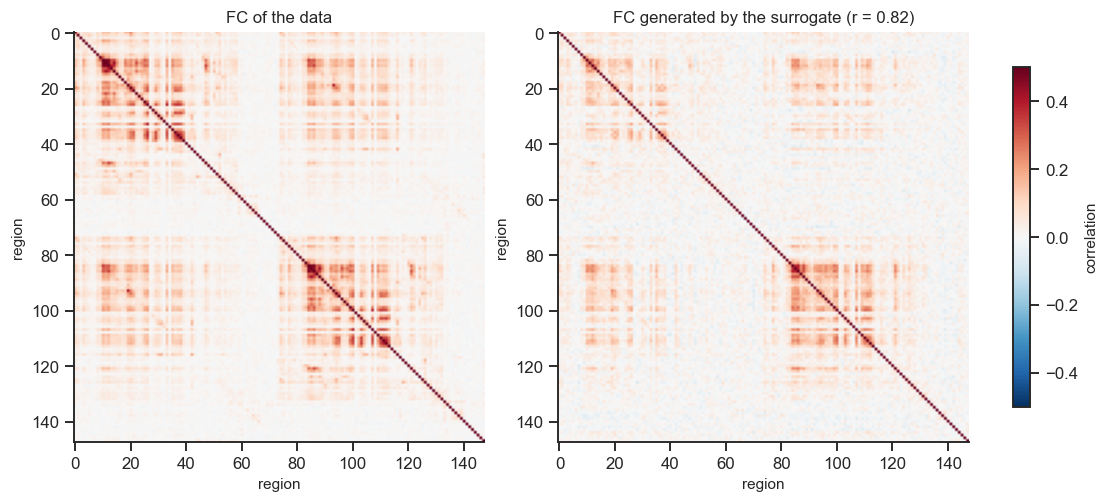

In [4]:
# @title Generate 3000 frames with the trained MLP (prediction fed back + noise) and compare the FC with the data
with torch.no_grad():
    noise = (mlp(Xtr) - Ytr).std(0)                             # size of what the network cannot predict, per region
    win, gen = Xte[0].clone(), []
    for k in range(3000):
        nxt = mlp(win[None])[0] + noise * torch.randn(N)
        gen.append(nxt.numpy()); win = torch.cat([win[1:], nxt[None]])
gen = np.array(gen)
FC_data, FC_gen = np.corrcoef(data[:n_train].T), np.corrcoef(gen.T)
u = np.triu_indices(N, 1); r = np.corrcoef(FC_data[u], FC_gen[u])[0, 1]
fig, ax = plt.subplots(1, 2, figsize=(10, 4.4), layout="constrained")
for a_, M, title in [(ax[0], FC_data, "FC of the data"), (ax[1], FC_gen, f"FC generated by the surrogate (r = {r:.2f})")]:
    im = a_.imshow(M, cmap="RdBu_r", vmin=-0.5, vmax=0.5); a_.set(title=title, xlabel="region", ylabel="region")
fig.colorbar(im, ax=ax, label="correlation", shrink=0.8); plt.show()

The network was trained only to predict one frame ahead, yet running on its own it reproduces the FC of the data
(r = similarity of the two matrices, off-diagonal entries).

## 4. Perturb the surrogate: effective connectivity (NPI)

> **Gist.** The same virtual experiment as NB14b, on a learned model instead of a built one. Push region $j$ by one
> standard deviation in the last input frame and record how the predicted next frame changes in every region $i$;
> repeat for every $j$. The table "push $j$ → change in $i$" is the **effective
> connectivity (EC)**. Unlike FC, it has a direction. Here we can compare it with the true wiring.

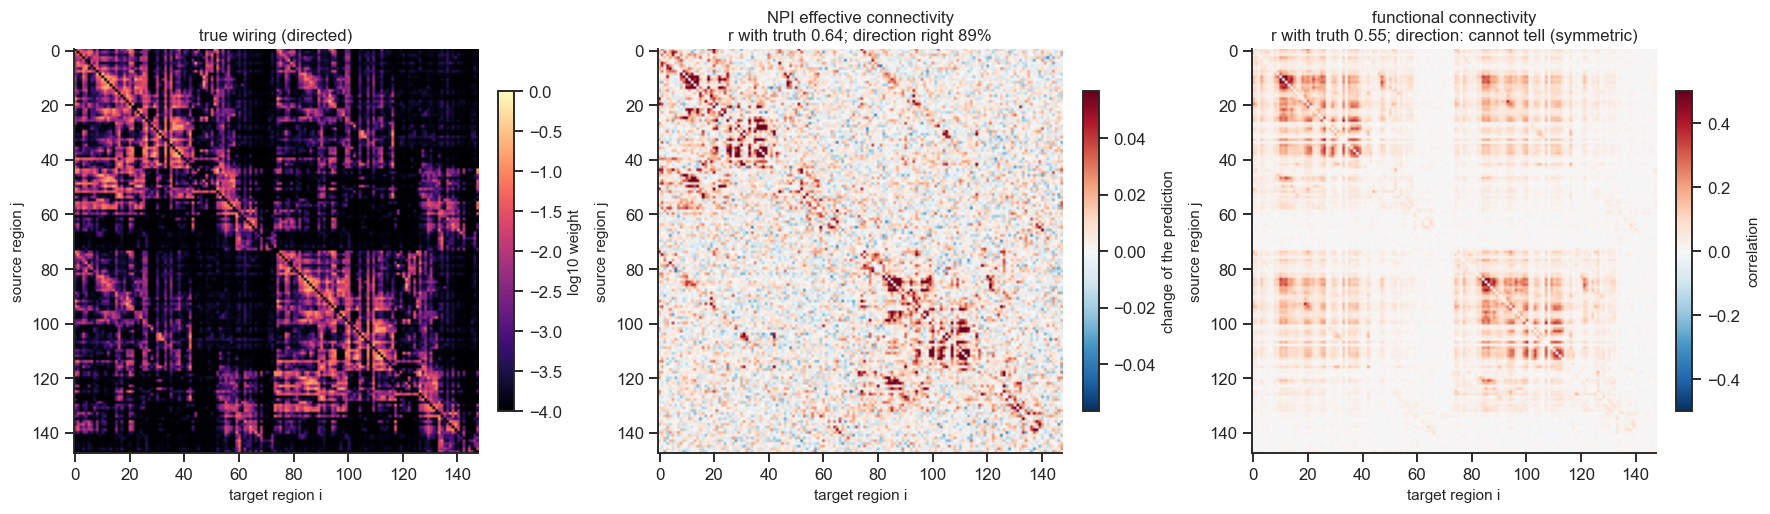

direction of the 10 % most one-way connections: NPI right in 89% of cases; FC is symmetric, so it cannot tell (chance 50 %)


In [5]:
# @title Neural Perturbational Inference: push each region in turn and read the change of the prediction
def npi_ec(model, X, size=1.0):
    with torch.no_grad():
        base = model(X); EC = np.zeros((N, N))
        for j in range(N):
            Xp = X.clone(); Xp[:, -1, j] += size                    # push region j in the most recent frame
            EC[j] = (model(Xp) - base).mean(0).numpy()               # EC[j, i]: effect of j on i
    np.fill_diagonal(EC, 0); return EC

def scores(EC):
    # how often the direction of the 10 % most one-way connections is right, and similarity with the true wiring
    i, j = np.where(np.triu(np.ones((N, N)), 1)); asym = true[i, j] - true[j, i]
    oneway = np.abs(asym) > np.percentile(np.abs(asym), 90)
    direction = np.mean(np.sign(EC[i, j] - EC[j, i])[oneway] == np.sign(asym)[oneway])
    off = ~np.eye(N, dtype=bool)
    return direction, np.corrcoef(EC[off], true[off])[0, 1]

EC = npi_ec(mlp, Xte)
FC0 = FC_data.copy(); np.fill_diagonal(FC0, 0)
(d_ec, r_ec), (d_fc, r_fc) = scores(EC), scores(FC0)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), layout="constrained")
im0 = ax[0].imshow(np.log10(true + 1e-4), cmap="magma", vmin=-4, vmax=0); ax[0].set_title("true wiring (directed)")
fig.colorbar(im0, ax=ax[0], label="log10 weight", shrink=0.7)
v = np.percentile(np.abs(EC), 99)
im1 = ax[1].imshow(EC, cmap="RdBu_r", vmin=-v, vmax=v); ax[1].set_title(f"NPI effective connectivity\nr with truth {r_ec:.2f}; direction right {d_ec:.0%}")
fig.colorbar(im1, ax=ax[1], label="change of the prediction", shrink=0.7)
im2 = ax[2].imshow(FC0, cmap="RdBu_r", vmin=-0.5, vmax=0.5); ax[2].set_title(f"functional connectivity\nr with truth {r_fc:.2f}; direction: cannot tell (symmetric)")
fig.colorbar(im2, ax=ax[2], label="correlation", shrink=0.7)
for a_ in ax: a_.set(xlabel="target region i", ylabel="source region j")
plt.show()
print(f"direction of the 10 % most one-way connections: NPI right in {d_ec:.0%} of cases; "
      f"FC is symmetric, so it cannot tell (chance 50 %)")

The surrogate was never told the wiring. Its EC resembles the wiring only a little more than FC does (r in the
titles), but perturbing it recovers the **direction** of most one-way connections, which FC cannot do. This is the validation step of the slides: test the method on a system like your data where the answer is
known. (On a nonlinear, slow BOLD signal it is harder: see Homework 4.)

### Explore: how much data does the surrogate need?

Retrain the MLP on the first part of the training data only (a few seconds per change) and look at the gap between
training and test loss, and at how well NPI recovers the wiring.

In [6]:
# @title Explore: train on fewer frames and compare losses and NPI with the truth
@interact(frames=slider(2000, 500, 18000, 500, "training frames"))
def explore_data_size(frames):
    frames = int(frames)                                              # sliders give decimals
    model, h = train(make_mlp(), Xtr[:frames], Ytr[:frames], Xte, Yte, epochs=15)
    d, rr = scores(npi_ec(model, Xte))
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw=dict(width_ratios=[1.4, 1]))
    e = np.arange(1, len(h) + 1)
    ax[0].plot(e, h[:, 0], "o-", c="C0", label="training data"); ax[0].plot(e, h[:, 1], "o-", c="C3", label="test data")
    ax[0].set(xlabel="epoch", ylabel="loss", title=f"trained on {frames} frames"); ax[0].legend(fontsize=8)
    ax[1].bar(["direction right\n(one-way links)", "r(EC, true wiring)"], [d, rr], color=["C2", "C4"])
    ax[1].axhline(0.5, c="0.5", ls=":", lw=1, label="chance for direction"); ax[1].set(ylim=(0, 1), title="NPI vs the truth")
    ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

## Take-home

* Trained to predict the next frame, an MLP becomes a **surrogate** of the system: judge it by the **test** loss, and
  stop before it overfits.
* Running on its own, the surrogate generates activity with the FC of the data.
* Perturbing it (NPI) gives a **directed** effective connectivity, which we validate where the truth is known.
* On real fMRI, one surrogate per person lets us run the stimulation experiments of NB14b on a model learned from that
  person, and ask **where** and **when** to stimulate (slides; Rabuffo et al. 2026).

### Homework
*To do at home, after the class.*
1. **Real data.** Train the MLP on one participant of NB09 (`../data/empirical/fmri_ds000228_schaefer100.npz`, key `ts`:
   10 people × 168 frames × 100 regions). How large is the gap between training and test loss? Why?
2. **The linear baseline.** Replace the MLP by a VAR, `nn.Sequential(nn.Flatten(), nn.Linear(S * N, N))`. Compare its
   test loss and its NPI with the MLP's. Which one should win on this (linear) brain?
3. **Memory.** Train with $S=1$ and $S=6$ past frames (change `S` and rebuild the windows). Does the test loss change?
4. **A hard case.** Train on simulated BOLD of the bistable model of NB11 run on the **mouse** connectome (an earlier
   version of NB11; `../data/cache/nb11_bold.npz`, key `bold`: 6 runs × 580 s × 148 regions, made by
   `dev/cache_nb11.py`) and test the direction of one-way links against `scm.T`. Why is it harder?

### References
* Luo Z, Peng K, Liang Z, Cai S, Xu C, Li D, Hu Y, Zhou C, Liu Q (2025). Mapping effective connectivity by virtually
  perturbing a surrogate brain. *Nat Methods* 22:1376–1385.
* Rabuffo G, Acero-Pousa I, Berjaga-Buisan T, Deco G (2026). A personalized map of where, when, and how to stimulate the
  brain to elicit controlled responses. *bioRxiv* doi:10.64898/2026.07.16.738930 (code: github.com/grabuffo/ANN_Stim).
* Goodfellow I, Bengio Y, Courville A (2016). *Deep Learning*. MIT Press (free online), ch. 5–6.